# Simulate Observations

An observing system simulation experiment (OSSE) assimilates simulated observations of a nature run (a simulation
of the atmosphere taken as the truth) to measure the value of an observing system. Simulating an observation has two
parts: *where, when, and how well* it is made (its place and time, the footprint over which it averages the scene,
and the size of its error), which depend on the observing system; and *what* it measures (the radiances or retrieved
quantities that a forward model computes from the scene). TAT-C models the first part, which this notebook walks
through; the forward model and the errors' magnitudes come from the user.

The notebook simulates a day of observations of the American Southwest by the microwave and infrared sounders of
NOAA-20 and NOAA-21 (ATMS and CrIS):

1. it collects the samples of each sounder (`collect_ground_pixels`) and assesses their quality: their footprints and
   the resolution they bound, and the instruments' nominal performance at each sample's slant range
   (`compute_observation_quality`);
2. it samples a field of the GEOS-5 Nature Run over the footprint of each sample (`sample_field` with
   `method="footprint"`), and compares it with the field at the sample's center;
3. it adds simulated errors (`simulate_observation_errors`);
4. it samples profiles of a field with levels at the tangent points of a notional limb sounder (`sample_profiles`);
5. it writes the observations as IODA files for a data assimilation system of JEDI (`tatc.export.to_ioda`),
   including the sets of a data denial experiment, each without one satellite.

The field sampled here is the upwelling longwave flux at the top of the atmosphere, which stands in for a
measurement: a real OSSE would apply a forward model (such as a radiative transfer model) to the nature run's fields
at each footprint.

In [1]:
from datetime import datetime, timedelta, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from shapely.geometry import box

DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# study region: the American Southwest, as in the monsoon OSSE
domain = box(-115, 31, -103, 38)
# a day of simulated orbits, and the nature run of the same calendar date in the Nature Run's first year
start = datetime(2026, 7, 16, tzinfo=timezone.utc)
end = start + timedelta(days=1)
nature_start = start.replace(year=2005)
frame_duration = timedelta(minutes=30)  # the Nature Run's time-averaging interval
BLUE, ORANGE, GRAY = "#2a78b6", "#e06c1f", "#8a8984"

## Load the Nature Run

The nature run is the 7-km GEOS-5 Nature Run (G5NR; Gelaro et al., 2015), whose 30-minute means of the upwelling
longwave flux (`lwtup`) over the study region are downloaded once (two days, shared with the monsoon OSSE). Its
times are moved to the simulated year, so that the satellites' times index it directly; each time is the middle of
its averaging interval, so that `sample_field` takes the interval in which an observation falls (its nearest time).

In [2]:
G5NR_URL = "https://opendap.nccs.nasa.gov/dods/OSSE/G5NR/Ganymed/7km/0.0625_deg/tavg/tavg30mn_2d_met3_Nx"


def load_nature(days=2):
    """The Nature Run over the study region for days from nature_start, downloaded once to DATA_DIR."""
    nature_file = DATA_DIR / f"g5nr_{nature_start:%Y%m%d}_{days}d.nc"
    if not nature_file.exists():
        minx, miny, maxx, maxy = domain.bounds
        with xr.open_dataset(G5NR_URL, decode_times=True) as remote:
            remote[["lwtup", "preccon"]].sel(
                time=slice(
                    nature_start.replace(tzinfo=None),
                    (nature_start + timedelta(days=days)).replace(tzinfo=None),
                ),
                lon=slice(minx, maxx),
                lat=slice(miny, maxy),
            ).load().to_netcdf(nature_file)
    return xr.load_dataset(nature_file)


nature = load_nature()
# the field of the simulated day: the flux, at the times of the simulated year
offset = np.timedelta64(start.replace(tzinfo=None) - nature_start.replace(tzinfo=None))
field = nature["lwtup"].assign_coords(time=nature.time.values + offset)
print(
    f"{field.sizes['time']} frames of {field.sizes['lat']} x {field.sizes['lon']} cells, "
    f"{pd.Timestamp(field.time.values[0]):%Y-%m-%d %H:%M} to "
    f"{pd.Timestamp(field.time.values[-1]):%Y-%m-%d %H:%M} UTC (centers of 30-minute means)"
)

C:\Users\pgrogan1\github\tatc\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


96 frames of 113 x 193 cells, 2026-07-16 00:15 to 2026-07-17 23:45 UTC (centers of 30-minute means)


## Define the Observing Systems

The orbits of NOAA-20 and NOAA-21 come from element sets of the JPSS archive (as in the monsoon OSSE), and their
sounders from TAT-C's [instrument catalog](../../validation/catalog.rst): the configurations of their samples on
NOAA-20, which were tested against its data (`beams_noaa_20` of ATMS, whose temperature-sounding channels 3 to 16
have a 2.2 degree beam, and `pixels_noaa_20` of CrIS, its 3 x 3 array of fields of view), with the attitude in
which they scan. The catalog gives each instrument its nominal performance (the ground sample distance at nadir from
a reference altitude, scaled by a power law of the altitude, see `InstrumentPerformance`), with its source.

In [3]:
from tatc.catalog import get_entry
from tatc.schemas import GeneralPerturbationsOrbit, Satellite

tles = {
    "NOAA-20": [
        "1 43013U 17073A   26197.00000000  .00000069  00000-0  32863-4 0  1908",
        "2 43013  98.7768 136.2093 0001592 131.9807  15.3167 14.19516563448569",
    ],
    "NOAA-21": [
        "1 54234U 22150A   26197.00000000  .00000063  00000-0  30079-4 0  9591",
        "2 54234  98.7055 135.3072 0002920 108.6153 233.8084 14.19541053190632",
    ],
}
orbits = {name: GeneralPerturbationsOrbit.from_tle(tle) for name, tle in tles.items()}
atms = get_entry("atms").build(configuration="beams_noaa_20", orbit=orbits["NOAA-20"])
cris = get_entry("cris").build(configuration="pixels_noaa_20", orbit=orbits["NOAA-20"])
# the instrument of each sensor: ATMS's temperature-sounding channels, and CrIS
instruments = {"ATMS": atms.instruments[1], "CrIS": cris.instruments[0]}
satellites = [
    Satellite(
        name=name,
        orbit=orbit,
        instruments=list(instruments.values()),
        attitude=atms.attitude,
    )
    for name, orbit in orbits.items()
]
pd.DataFrame(
    {
        sensor: {
            "pixels per scan": instrument.cross_track_pixels
            * instrument.along_track_pixels,
            "scan period (s)": instrument.scan_period,
            "nominal ground sample distance (km)": instrument.performance.ground_sample_distance
            / 1e3,
            "reference altitude (km)": instrument.performance.reference_altitude / 1e3,
        }
        for sensor, instrument in instruments.items()
    }
).T.round(2)

,pixels per scan,scan period (s),nominal ground sample distance (km),reference altitude (km)
ATMS,96.0,2.67,32.0,824.0
CrIS,270.0,8.00,14.0,824.0


## Collect the Samples

Each sounder scans once per scan period, so its samples are collected at the start of every scan
(`collect_ground_pixels`) while its satellite passes over the study region (found from the subsatellite point every
30 s). `compute_observation_quality` then gives each sample its footprint along and across track and its azimuth on
the ground (see `compute_sample_sizes`), the resolution it bounds (the larger of the footprint and the spacing of the
samples), and the instrument's nominal ground sample distance and noise scale at the sample's slant range. Both
sounders are passive, so their noise does not scale with the range (a noise scale of 1); an active instrument's
noise would grow off nadir.

In [4]:
from skyfield.api import wgs84

from tatc.analysis import collect_ground_pixels, compute_observation_quality


def overpass_times(satellite, period):
    """The times, every scan period, while a satellite's subsatellite point is within 15 degrees of the region."""
    coarse = [
        start + timedelta(seconds=30 * k)
        for k in range(int((end - start).total_seconds() // 30))
    ]
    point = wgs84.subpoint_of(satellite.get_track(coarse))
    lon, lat = point.longitude.degrees, point.latitude.degrees
    center = domain.centroid
    near = (np.abs(lat - center.y) < 15) & (
        np.abs((lon - center.x + 180) % 360 - 180) < 25
    )
    times = []
    for time in np.array(coarse)[near]:
        times += [
            time + timedelta(seconds=period * k) for k in range(int(30 // period) + 1)
        ]
    return sorted(set(times))


samples = []
for satellite in satellites:
    for index, (sensor, instrument) in enumerate(instruments.items()):
        pixels = collect_ground_pixels(
            satellite,
            overpass_times(satellite, instrument.scan_period),
            instrument_index=index,
            mask=domain,
            platform_altaz=True,
            solar_altaz=True,
        )
        pixels = pixels[pixels.valid_obs].assign(sensor=sensor)
        samples.append(compute_observation_quality(pixels, satellite))
samples = pd.concat(samples, ignore_index=True)
nadir = samples.scan_angle.abs() < 5
edge = samples.scan_angle.abs() > 45
pd.DataFrame(
    {
        sensor: {
            "samples": int((samples.sensor == sensor).sum()),
            "resolution at nadir, along x across (km)": "{:.1f} x {:.1f}".format(
                *samples[nadir & (samples.sensor == sensor)][
                    ["resolution_along", "resolution_cross"]
                ].median()
                / 1e3
            ),
            "resolution at the edge, along x across (km)": "{:.1f} x {:.1f}".format(
                *samples[edge & (samples.sensor == sensor)][
                    ["resolution_along", "resolution_cross"]
                ].median()
                / 1e3
            ),
            "nominal ground sample distance at nadir (km)": round(
                samples[
                    nadir & (samples.sensor == sensor)
                ].ground_sample_distance.median()
                / 1e3,
                1,
            ),
            "noise scale": samples[samples.sensor == sensor].noise_scale.median(),
        }
        for sensor in instruments
    }
).T

,samples,"resolution at nadir, along x across (km)","resolution at the edge, along x across (km)",nominal ground sample distance at nadir (km),noise scale
ATMS,8827,31.9 x 32.0,54.5 x 106.6,32.3,1.0
CrIS,8269,17.8 x 16.1,25.5 x 46.7,14.1,1.0


## Sample the Nature Run over the Footprints

A sounder measures the scene averaged over its footprint, which is tens of kilometers wide for ATMS and grows toward
the edges of the swath. `sample_field` with `method="footprint"` averages the nature run's cells weighted by a
Gaussian whose full widths at half maximum are the footprint's sizes along and across track, oriented by its
azimuth, at the frame of the nature run in which the sample falls. The difference from the field at the footprint's
center (`method="nearest"`) is the error of representing the footprint by a point, which grows with the footprint's
size; the footprints of CrIS, nearly as small as the nature run's 7 km cells, differ least.

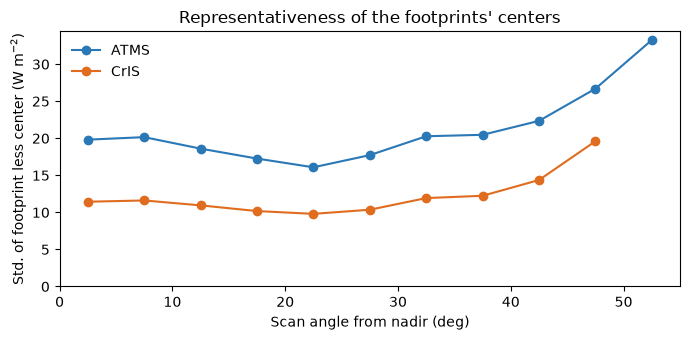

sensor                         ATMS     CrIS
lwtup                count  8821.00  8269.00
                     mean    252.51   252.81
                     std      37.54    41.93
                     min     134.16   120.19
                     25%     231.37   232.12
                     50%     255.78   257.86
                     75%     276.76   279.39
                     max     345.50   349.95
lwtup_valid_fraction count  8827.00  8269.00
                     mean      0.97     0.99
                     std       0.08     0.04
                     min       0.33     0.52
                     25%       1.00     1.00
                     50%       1.00     1.00
                     75%       1.00     1.00
                     max       1.00     1.00
difference           count  8821.00  8269.00
                     mean      0.27    -0.08
                     std      21.26    12.53
                     min     -98.11   -88.45
                     25%     -11.07    -5.01
                     50%      -1.78    -0.35
                     75%       8.52     4.20
                     max     131.32    79.44

In [5]:
from tatc.analysis import sample_field

sampled = sample_field(samples, field, name="lwtup", method="footprint")
sampled = sample_field(sampled, field, name="lwtup_center")
sampled["difference"] = sampled.lwtup - sampled.lwtup_center
bins = np.arange(0, 60, 5)
fig, ax = plt.subplots(figsize=(7, 3.5))
for sensor, color in zip(instruments, (BLUE, ORANGE)):
    group = sampled[sampled.sensor == sensor]
    spread = group.groupby(
        pd.cut(group.scan_angle.abs(), bins), observed=True
    ).difference.std()
    ax.plot(
        [b.mid for b in spread.index], spread.values, "o-", color=color, label=sensor
    )
ax.set(
    xlabel="Scan angle from nadir (deg)",
    ylabel="Std. of footprint less center (W m$^{-2}$)",
    title="Representativeness of the footprints' centers",
    ylim=(0, None),
)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
sampled.groupby("sensor")[
    ["lwtup", "lwtup_valid_fraction", "difference"]
].describe().T.round(2)

The map shows one pass of NOAA-21 over the study region: the nature run's frame at the time of the pass, and the
flux of each footprint of ATMS and CrIS, drawn at its center. ATMS's large footprints smooth the convective cells
that CrIS resolves.

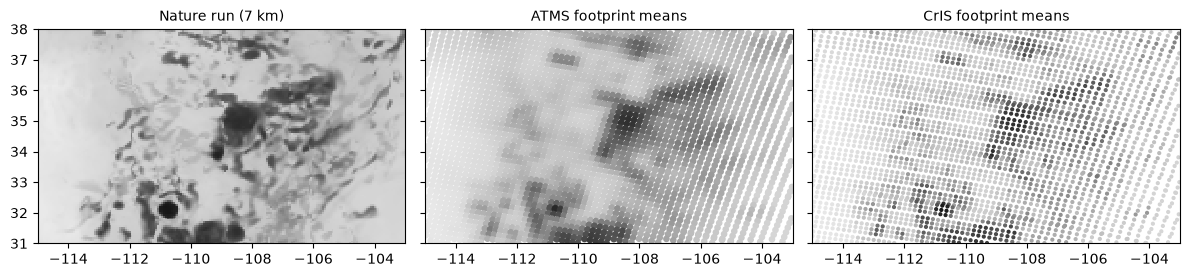

In [6]:
first_pass = sampled[(sampled.satellite == "NOAA-21")]
first_pass = first_pass[first_pass.time < first_pass.time.min() + timedelta(minutes=20)]
frame = field.sel(time=first_pass.time.min().tz_convert(None), method="nearest")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
style = {"cmap": "Greys_r", "vmin": 100, "vmax": 350}
axes[0].pcolormesh(frame.lon, frame.lat, frame, shading="nearest", **style)
axes[0].set_title("Nature run (7 km)", fontsize=10)
for ax, sensor in zip(axes[1:], instruments):
    group = first_pass[first_pass.sensor == sensor]
    ax.scatter(
        group.geometry.x,
        group.geometry.y,
        c=group.lwtup,
        s=4 if sensor == "CrIS" else 14,
        **style,
    )
    ax.set_title(f"{sensor} footprint means", fontsize=10)
for ax in axes:
    ax.set(xlim=(-115, -103), ylim=(31, 38), aspect="equal")
fig.tight_layout()
plt.show()

## Simulate the Errors

`simulate_observation_errors` adds random errors drawn from a normal distribution whose standard deviation the
user gives (here, illustrative values for each sensor at its reference altitude), scaled by each sample's noise
scale (1 for these passive sounders), and gives the standard deviation of each error (`lwtup_error_std`) and the
observed value (`lwtup_observed`). A seed makes the errors reproducible. The errors are independent; errors that are
correlated between samples (such as those of a scan) are not simulated.

In [7]:
from tatc.analysis import simulate_observation_errors

ERROR_STD = {"ATMS": 3.0, "CrIS": 1.5}  # W m-2, illustrative
sampled["error_std"] = sampled.sensor.map(ERROR_STD)
observed = simulate_observation_errors(
    sampled, "lwtup", standard_deviation="error_std", seed=2026
)
observed.groupby("sensor").apply(
    lambda group: pd.Series(
        {
            "error std (W m-2)": group.lwtup_error_std.median(),
            "observed less footprint, std (W m-2)": (
                group.lwtup_observed - group.lwtup
            ).std(),
        }
    ),
    include_groups=False,
).round(2)

,error std (W m-2),"observed less footprint, std (W m-2)"
sensor,,
ATMS,3.0,3.00
CrIS,1.5,1.51


## Sample Profiles at Tangent Points

A limb sounder views the atmosphere edge-on, at tangent points whose heights span a profile. `sample_profiles`
samples a field with levels at each tangent point's height, interpolating between the field's levels (here a
notional temperature field on height levels: a standard lapse rate in the troposphere, an isothermal lower
stratosphere, and a wave of 5 K in longitude), and gives each point a row, with the observation it belongs to. The
notional limb sounder flies in NOAA-21's orbit, looking forward, and scans from 5 to 45 km every 30 s for an hour; the
figure shows three of its profiles, 20 minutes apart.

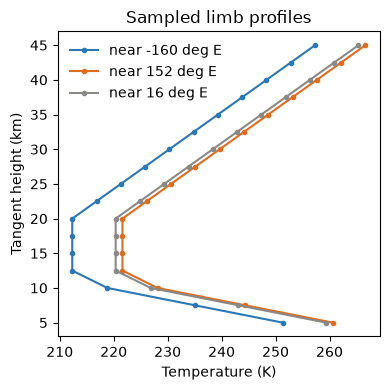

120 scans, 2040 tangent points


In [8]:
from tatc.analysis import collect_limb_soundings, sample_profiles
from tatc.schemas import LimbSounder

heights = np.arange(0.0, 50001.0, 1000.0)
lat = np.arange(-90.0, 90.1, 1.0)
lon = np.arange(-180.0, 180.0, 1.0)
standard = np.interp(heights, [0, 11e3, 20e3, 50e3], [288.15, 216.65, 216.65, 270.65])
temperature = xr.DataArray(
    standard[None, :, None, None]
    + 5 * np.sin(np.radians(3 * lon))[None, None, None, :]
    + 0 * lat[None, None, :, None],
    dims=("time", "level", "lat", "lon"),
    coords={
        "time": [np.datetime64(start.replace(tzinfo=None))],
        "level": heights,
        "lat": lat,
        "lon": lon,
    },
    name="temperature",
)
sounder = LimbSounder(
    name="Limb sounder",
    scan_azimuth=0,
    scan_elevations=list(np.arange(5e3, 45001, 2.5e3)),
    scan_duration=timedelta(seconds=20),
    cycle_period=timedelta(seconds=30),
)
limb = Satellite(name="Limb", orbit=orbits["NOAA-21"], instruments=[sounder])
scans = collect_limb_soundings(limb, start, start + timedelta(hours=1))
profiles = sample_profiles(scans, temperature)
fig, ax = plt.subplots(figsize=(4, 4))
for observation, color in zip(
    profiles.observation.unique()[::40], (BLUE, ORANGE, GRAY)
):
    profile = profiles[profiles.observation == observation]
    longitude = profile.geometry.x.mean()
    ax.plot(
        profile.temperature,
        profile.height / 1e3,
        "o-",
        color=color,
        ms=3,
        label=f"near {longitude:.0f} deg E",
    )
ax.set(
    xlabel="Temperature (K)",
    ylabel="Tangent height (km)",
    title="Sampled limb profiles",
)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
print(f"{len(scans)} scans, {len(profiles)} tangent points")

## Write the Observations for Data Assimilation

`tatc.export.to_ioda` writes the observations as an IODA file of JEDI's data assimilation systems: their places and
times (`MetaData`), with the viewing geometry (the sensor and solar zenith and azimuth angles); the observed values
(`ObsValue`), named as JEDI's UFO names its variables (here a placeholder name); and the standard deviations of their
errors (`ObsError`, found by their names). A data denial experiment assimilates the observations without those of
one member of the observing system, to measure its value: the control set and each satellite's denial set are
written to their own files. (`tatc.export.to_cf_netcdf` writes CF-netCDF point files for other tools.)

In [9]:
import netCDF4

from tatc.export import to_ioda

files = {}
experiments = {"control": []} | {f"deny {s.name}": [s.name] for s in satellites}
for experiment, denied in experiments.items():
    for sensor in instruments:
        chosen = observed[
            (observed.sensor == sensor) & ~observed.satellite.isin(denied)
        ]
        path = DATA_DIR / f"{experiment.replace(' ', '_')}_{sensor.lower()}.nc4"
        to_ioda(
            chosen,
            path,
            variables={"lwtup_observed": "upwellingLongwaveFlux"},
            units={"lwtup_observed": "W m-2"},
        )
        with netCDF4.Dataset(path) as dataset:
            files[(experiment, sensor)] = {
                "observations": len(dataset.dimensions["Location"]),
                "groups": ", ".join(dataset.groups),
                "metadata": len(dataset["MetaData"].variables),
            }
pd.DataFrame(files).T

observations                               groups metadata
control      ATMS         8827  MetaData, ObsValue, ObsError, PreQC        8
             CrIS         8269  MetaData, ObsValue, ObsError, PreQC        8
deny NOAA-20 ATMS         5200  MetaData, ObsValue, ObsError, PreQC        8
             CrIS         5202  MetaData, ObsValue, ObsError, PreQC        8
deny NOAA-21 ATMS         3627  MetaData, ObsValue, ObsError, PreQC        8
             CrIS         3067  MetaData, ObsValue, ObsError, PreQC        8

## Summary

TAT-C simulates where, when, and how well an observing system observes a nature run: the samples of each sensor and
their quality, the nature run averaged over each footprint (or at heights, for limb profiles), observation errors of
a size the user gives, and the files of a data assimilation system for the control and denial experiments of an
OSSE. A real OSSE replaces the field sampled here with the output of a forward model at each footprint, and the
illustrative error sizes with those of the instruments; regional nature runs on curvilinear grids (as WRF's) and
global ones on unstructured meshes (as MPAS's) are sampled the same way.

**Reference.** Gelaro, R., et al. (2015). Evaluation of the 7-km GEOS-5 Nature Run. NASA Technical Report Series on
Global Modeling and Data Assimilation, Volume 36, NASA/TM-2014-104606.